In [40]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow Version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow Version: 2.21.0
Libraries imported successfully!


In [41]:
# Load the Fashion MNIST dataset
fashion_mnist = keras.datasets.fashion_mnist

(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

# Display dataset shapes
print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)

print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


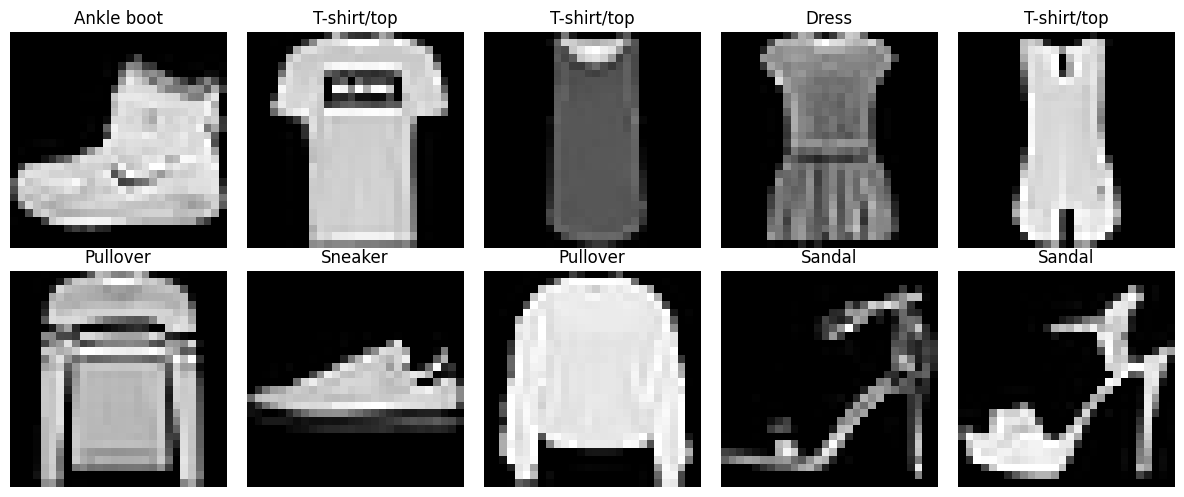

In [42]:
# Names of the 10 clothing categories
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

# Display the first 10 training images
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(class_names[y_train[i]])
    plt.axis('off')

plt.tight_layout()
plt.show()

In [43]:
# Normalize pixel values
X_train = X_train / 255.0
X_test = X_test / 255.0

print("Training data range:", X_train.min(), "to", X_train.max())
print("Testing data range:", X_test.min(), "to", X_test.max())

Training data range: 0.0 to 1.0
Testing data range: 0.0 to 1.0


In [44]:
# Build the CNN model
model = keras.Sequential([

    # Input layer
    layers.Input(shape=(28, 28, 1)),

    # First convolutional layer
    layers.Conv2D(32, (3, 3), activation='relu'),

    # Pooling layer
    layers.MaxPooling2D((2, 2)),

    # Second convolutional layer
    layers.Conv2D(64, (3, 3), activation='relu'),

    # Pooling layer
    layers.MaxPooling2D((2, 2)),

    # Flatten the feature maps
    layers.Flatten(),

    # Fully connected layer
    layers.Dense(128, activation='relu'),

    # Output layer (10 clothing categories)
    layers.Dense(10, activation='softmax')
])

# Display model architecture
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [45]:
# Compile the CNN model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 50s 65ms/step - accuracy: 0.8169 - loss: 0.5124 - val_accuracy: 0.8673 - val_loss: 0.3702
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 46s 61ms/step - accuracy: 0.8790 - loss: 0.3365 - val_accuracy: 0.8848 - val_loss: 0.3194
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 81s 60ms/step - accuracy: 0.8932 - loss: 0.2937 - val_accuracy: 0.8879 - val_loss: 0.3134
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 46s 62ms/step - accuracy: 0.9040 - loss: 0.2594 - val_accuracy: 0.9014 - val_loss: 0.2758
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 44s 59ms/step - accuracy: 0.9121 - loss: 0.2392 - val_accuracy: 0.8996 - val_loss: 0.2705
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 84s 62ms/step - accuracy: 0.9202 - loss: 0.2155 - val_accuracy: 0.9065 - val_loss: 0.2616
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 80s 59ms/step - accuracy: 0.9267 - loss: 0.1953 - val_accuracy: 0.9095 - val_loss: 0.2562
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 82s 59ms/step - accuracy: 0.9343 - loss: 0.1757 - 

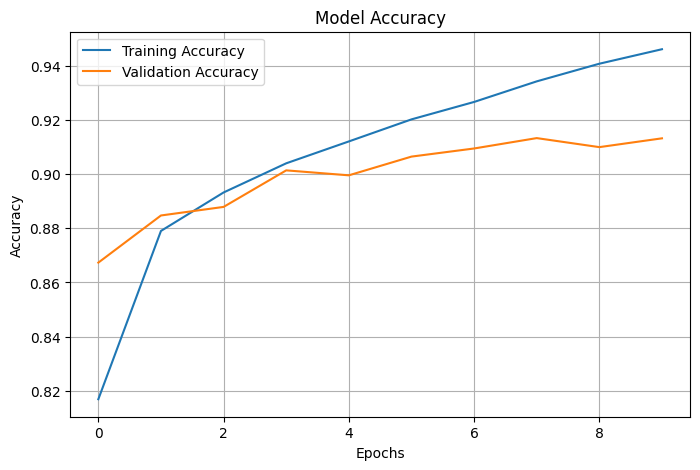

In [46]:
# Plot training and validation accuracy

plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

plt.show()

In [47]:
# Evaluate the model using test data

test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Test Loss:", round(test_loss, 4))

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.0959 - loss: 2.2972
Test Accuracy: 9.59 %
Test Loss: 2.2972


In [48]:
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining labels:")
print(np.unique(y_train))

print("\nTesting labels:")
print(np.unique(y_test))

print("\nTraining pixel range:", X_train.min(), X_train.max())
print("Testing pixel range:", X_test.min(), X_test.max())

Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)

Training labels:
[0 1 2 3 4 5 6 7 8 9]

Testing labels:
[0 1 2 3 4 5 6 7 8 9]

Training pixel range: 0.0 1.0
Testing pixel range: 0.0 1.0


In [49]:
# Get predictions for the first 10 test images
predictions = model.predict(X_test[:10])

predicted_labels = np.argmax(predictions, axis=1)

print("Actual labels:   ", y_test[:10])
print("Predicted labels:", predicted_labels)

print("\nPredicted probabilities:")
print(np.max(predictions, axis=1))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step
Actual labels:    [9 2 1 1 6 1 4 6 5 7]
Predicted labels: [2 2 0 0 2 0 0 2 2 2]

Predicted probabilities:
[0.10983703 0.11807197 0.11288197 0.11242335 0.11385215 0.11249801
 0.1052026  0.10889775 0.11052749 0.11241204]


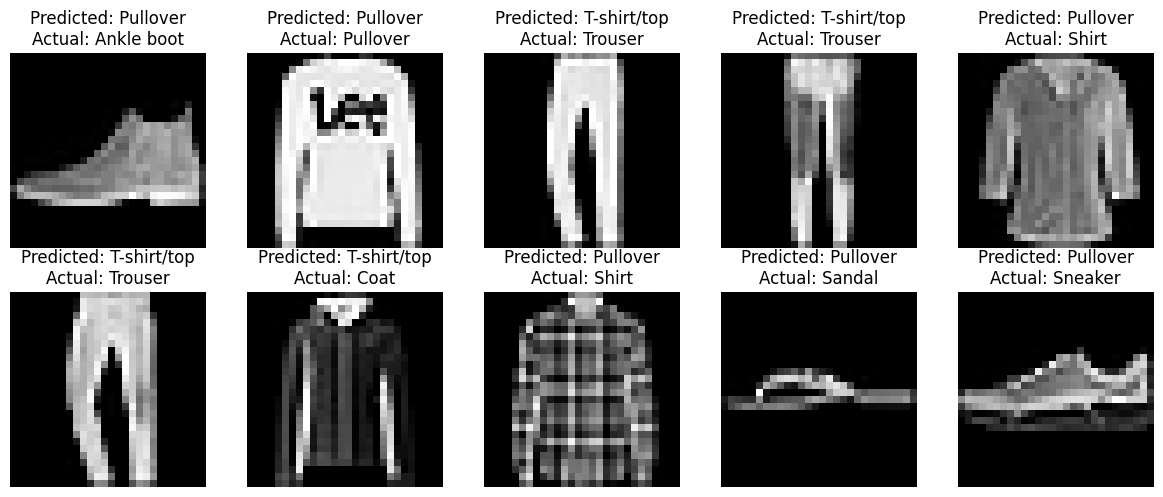

In [50]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i], cmap='gray')

    predicted = class_names[predicted_labels[i]]
    actual = class_names[y_test[i]]

    plt.title(f"Predicted: {predicted}\nActual: {actual}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [51]:
# Predict all test images
all_predictions = model.predict(X_test)

# Convert probabilities into class labels
predicted_classes = np.argmax(all_predictions, axis=1)

# Count predictions for each class
print("Predicted class distribution:")
print(np.bincount(predicted_classes, minlength=10))

print("\nActual class distribution:")
print(np.bincount(y_test, minlength=10))

# Calculate accuracy manually
manual_accuracy = np.mean(predicted_classes == y_test)

print("\nManual Test Accuracy:", manual_accuracy * 100, "%")

# Check training accuracy again
train_loss, train_accuracy = model.evaluate(X_train, y_train, verbose=0)

print("Training Accuracy:", train_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step
Predicted class distribution:
[5419  216 3672   26    1   49  545   62   10    0]

Actual class distribution:
[1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]

Manual Test Accuracy: 9.59 %
Training Accuracy: 9.584999829530716 %


In [53]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np

# Create CNN
final_model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])

# Compile
final_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train
history = final_model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.2
)

# Evaluate
test_loss, test_accuracy = final_model.evaluate(X_test, y_test)

print("\nFINAL TEST ACCURACY:", round(test_accuracy * 100, 2), "%")
print("FINAL TEST LOSS:", round(test_loss, 4))

# Check training accuracy
print("FINAL TRAINING ACCURACY:",
      round(history.history['accuracy'][-1] * 100, 2), "%")

Epoch 1/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 44s 113ms/step - accuracy: 0.7961 - loss: 0.5654 - val_accuracy: 0.8492 - val_loss: 0.4171
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 42s 111ms/step - accuracy: 0.8690 - loss: 0.3659 - val_accuracy: 0.8712 - val_loss: 0.3512
Epoch 3/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 82s 112ms/step - accuracy: 0.8858 - loss: 0.3153 - val_accuracy: 0.8854 - val_loss: 0.3121
Epoch 4/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 81s 110ms/step - accuracy: 0.8977 - loss: 0.2823 - val_accuracy: 0.8965 - val_loss: 0.2895
Epoch 5/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 42s 111ms/step - accuracy: 0.9046 - loss: 0.2606 - val_accuracy: 0.8972 - val_loss: 0.2835
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8933 - loss: 0.3014

FINAL TEST ACCURACY: 89.33 %
FINAL TEST LOSS: 0.3014
FINAL TRAINING ACCURACY: 90.46 %


313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step


<Figure size 1000x800 with 0 Axes>

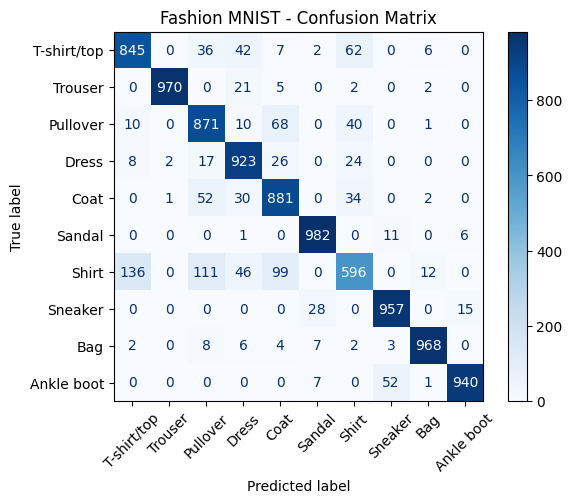

              precision    recall  f1-score   support

 T-shirt/top       0.84      0.84      0.84      1000
     Trouser       1.00      0.97      0.98      1000
    Pullover       0.80      0.87      0.83      1000
       Dress       0.86      0.92      0.89      1000
        Coat       0.81      0.88      0.84      1000
      Sandal       0.96      0.98      0.97      1000
       Shirt       0.78      0.60      0.68      1000
     Sneaker       0.94      0.96      0.95      1000
         Bag       0.98      0.97      0.97      1000
  Ankle boot       0.98      0.94      0.96      1000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



In [54]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# Predict test images
y_pred = np.argmax(final_model.predict(X_test), axis=1)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
disp.plot(cmap='Blues', xticks_rotation=45)
plt.title("Fashion MNIST - Confusion Matrix")
plt.show()

# Classification report
print(classification_report(y_test, y_pred, target_names=class_names))

In [55]:
final_model.save("Fashion_MNIST_CNN.keras")
print("Model saved successfully!")

Model saved successfully!
